# Actividad 5 – Regresión lineal simple, múltiple y logística
**Base:** `Datos_Complementarios_CLV.xlsx`

Este notebook detecta automáticamente los tipos de columnas. Solo coloca el archivo Excel en la misma carpeta y ejecuta todas las celdas (*Run All*).
Si quieres elegir tú las variables, cámbialas en la celda de **Configuración**.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             accuracy_score, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## Configuración

In [ ]:
ARCHIVO = "Datos_Complementarios_CLV.xlsx"
HOJA = 0                    # número o nombre de la hoja

# Déjalas en None para que se elijan automáticamente
Y_LINEAL = None             # variable cuantitativa dependiente (p. ej. "CLV")
VARIABLE_DICOTOMICA = None  # variable dicotómica para la regresión logística (p. ej. "Churn")

# Columnas que son identificadores o códigos (no son medidas) y no deben usarse en los modelos
EXCLUIR = ["articulo", "nombre_articulo"]

RANDOM_STATE = 42

## 1. Carga y exploración de la base

In [ ]:
df_raw = pd.read_excel(ARCHIVO, sheet_name=HOJA)
df = df_raw.copy()
df.columns = df.columns.astype(str).str.strip()
print("Dimensiones:", df.shape)
display(df.head())
df.info()

Dimensiones: (2951, 6)


,articulo,nombre_articulo,marca,almacen,existencias,valor_inventario
0,5804,CAMEO PRESS INGOT BOX HT A2,Aidite,Almacén General,1396,431773.71
1,5816,CAMEO PRESS INGOT BOX LT A1,Aidite,Almacén General,1043,316841.19
2,5762,CAMEO MILL BLOCS BOX C14 HT B1,Aidite,Almacén General,893,326871.85
3,212202,DIENTES HU TABLILLA ZAHN4ALL ANTERIOR SUPERIOR...,Huge,Almacén General,893,10368.49
4,5819,CAMEO PRESS INGOT BOX LT A2,Aidite,Almacén General,857,264454.69


<class 'pandas.DataFrame'>
RangeIndex: 2951 entries, 0 to 2950
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   articulo          2951 non-null   int64  
 1   nombre_articulo   2951 non-null   str    
 2   marca             2951 non-null   str    
 3   almacen           2951 non-null   str    
 4   existencias       2951 non-null   int64  
 5   valor_inventario  2951 non-null   float64
dtypes: float64(1), int64(2), str(3)
memory usage: 273.4 KB


In [ ]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
articulo,2951.0,NaN,NaN,NaN,3827014.674348,13208297.800076,3488.0,9084.5,11996.0,211975.5,71342123.0
nombre_articulo,2951,2951,CAMEO PRESS INGOT BOX HT A2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marca,2951,26,Vita,1810,NaN,NaN,NaN,NaN,NaN,NaN,NaN
almacen,2951,1,Almacén General,2951,NaN,NaN,NaN,NaN,NaN,NaN,NaN
existencias,2951.0,NaN,NaN,NaN,27.585564,82.059392,1.0,3.0,7.0,15.0,1396.0
valor_inventario,2951.0,NaN,NaN,NaN,23050.915507,134279.408206,0.0,1053.28,2340.51,6180.99,3644807.19


## 2. Preprocesamiento
### 2.1 Transformaciones de tipo
- Se eliminan columnas identificadoras o códigos (p. ej. clave del artículo): aunque sean números, no representan una cantidad.
- Se eliminan columnas constantes (un solo valor), porque no aportan información.
- Las fechas se convierten a número (días desde la fecha mínima).
- El texto se limpia (espacios, mayúsculas) y los números guardados como texto se convierten a numéricos.

In [ ]:
# Números guardados como texto -> numéricos
texto = lambda d: [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])
                   and not pd.api.types.is_datetime64_any_dtype(d[c])]
for c in texto(df):
    conv = pd.to_numeric(df[c].astype(str).str.replace(r"[$,%\s]", "", regex=True), errors="coerce")
    if conv.notna().mean() > 0.9:
        df[c] = conv

# Fechas -> días transcurridos
for c in df.columns:
    if pd.api.types.is_datetime64_any_dtype(df[c]):
        df[c] = (df[c] - df[c].min()).dt.days

# Duplicados (se revisan ANTES de quitar los códigos: dos productos distintos
# pueden tener la misma marca, existencias y valor, y no por eso son duplicados)
dup = df.duplicated().sum()
df = df.drop_duplicates()
print("Filas duplicadas eliminadas:", dup)

# Columnas identificadoras / códigos
claves = ["id", "codigo", "código", "clave", "sku", "folio"]
id_cols = [c for c in df.columns
           if c in EXCLUIR
           or any(k in c.lower().replace("_", " ").split() for k in claves)
           or (df[c].nunique() == len(df) and not pd.api.types.is_numeric_dtype(df[c]))]
df = df.drop(columns=id_cols)
print("Columnas ID / código eliminadas:", id_cols)

# Columnas constantes
constantes = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
df = df.drop(columns=constantes)
print("Columnas constantes eliminadas:", constantes)

# Limpieza de texto
for c in texto(df):
    df[c] = df[c].astype(str).str.strip().str.title().replace({"Nan": np.nan, "None": np.nan, "": np.nan})


Filas duplicadas eliminadas: 0
Columnas ID / código eliminadas: ['articulo', 'nombre_articulo']
Columnas constantes eliminadas: ['almacen']


### 2.2 Valores nulos
- Columnas con más de 50 % de nulos se eliminan.
- Numéricas: se imputan con la **mediana** (robusta a outliers).
- Categóricas: se imputan con la **moda**.

,nulos,%


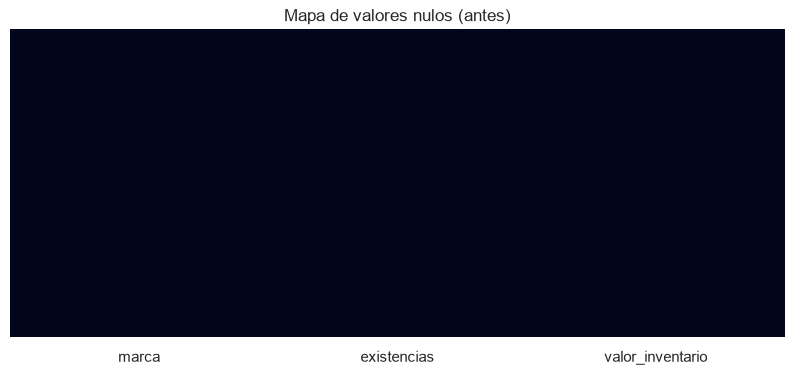

Columnas eliminadas por >50% nulos: []
Nulos restantes: 0


In [ ]:
nulos = pd.DataFrame({"nulos": df.isna().sum(), "%": (df.isna().mean()*100).round(2)})
display(nulos[nulos["nulos"] > 0].sort_values("%", ascending=False))

plt.figure(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Mapa de valores nulos (antes)")
plt.show()

muchos_nulos = nulos[nulos["%"] > 50].index.tolist()
df = df.drop(columns=muchos_nulos)
print("Columnas eliminadas por >50% nulos:", muchos_nulos)

for c in df.columns:
    if df[c].isna().any():
        if pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].fillna(df[c].median())
        else:
            df[c] = df[c].fillna(df[c].mode()[0])

print("Nulos restantes:", df.isna().sum().sum())

### 2.3 Transformación logarítmica
Las variables numéricas con asimetría fuerte (|skewness| > 1, típico en cantidades y montos) se transforman con
**log(1 + x)**. Esto reduce el efecto de los valores extremos sin eliminarlos y hace la relación más lineal.

### 2.4 Outliers (método IQR)
Se consideran outliers los valores fuera de **[Q1 − 1.5·IQR, Q3 + 1.5·IQR]**. En lugar de eliminar filas, se **acotan (winsorizan)** a esos límites para no perder registros. Las variables binarias no se tocan.

,skewness original
existencias,7.213
valor_inventario,16.601


Variables transformadas con log(1+x): ['existencias', 'valor_inventario']
Numéricas continuas: ['log_existencias', 'log_valor_inventario']
Binarias: []
Categóricas: ['marca']


,variable,outliers,lim_inf,lim_sup
0,log_existencias,138,-0.693147,4.852030
1,log_valor_inventario,232,4.307440,11.382568


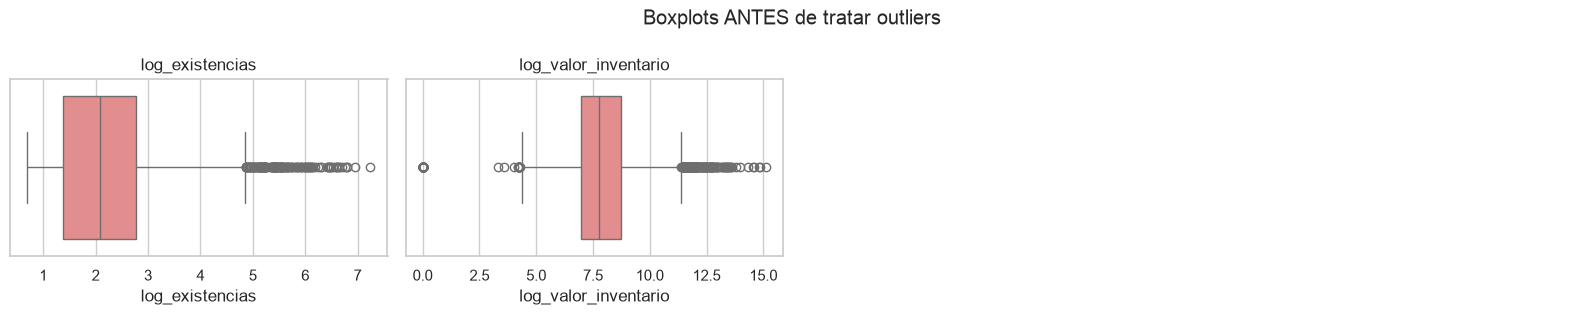

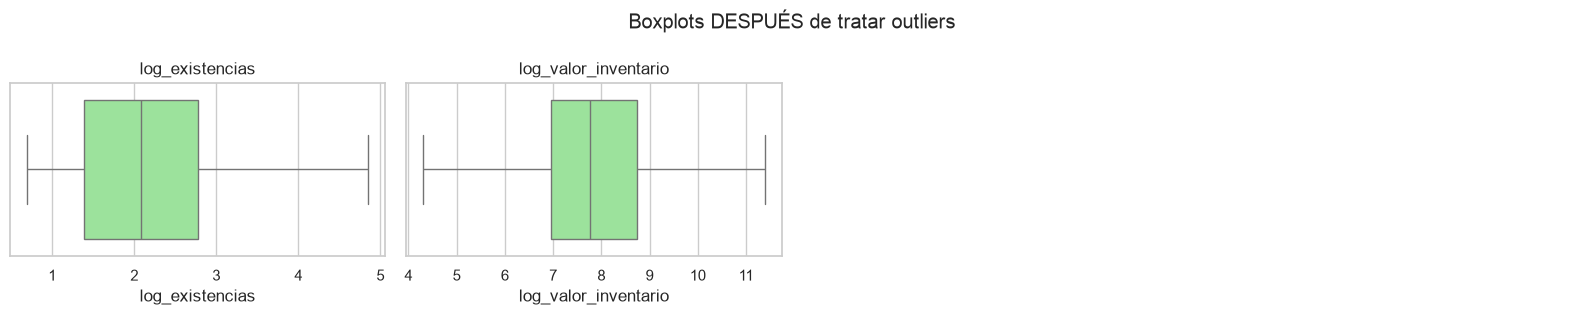

Outliers restantes: 0


In [ ]:
num_cols = [c for c in df.select_dtypes(include=np.number).columns if df[c].nunique() > 2]

asim = df[num_cols].skew()
display(asim.round(3).to_frame("skewness original"))
transformadas = []
for c in num_cols:
    if abs(asim[c]) > 1 and df[c].min() >= 0:
        df[f"log_{c}"] = np.log1p(df[c]); df = df.drop(columns=c); transformadas.append(c)
print("Variables transformadas con log(1+x):", transformadas)

num_cols = [c for c in df.select_dtypes(include=np.number).columns if df[c].nunique() > 2]
bin_cols = [c for c in df.columns if df[c].nunique() == 2]
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and c not in bin_cols]
print("Numéricas continuas:", num_cols)
print("Binarias:", bin_cols)
print("Categóricas:", cat_cols)

def resumen_outliers(data):
    filas = []
    for c in num_cols:
        q1, q3 = data[c].quantile([.25, .75]); iqr = q3 - q1
        li, ls = q1 - 1.5*iqr, q3 + 1.5*iqr
        filas.append([c, ((data[c] < li) | (data[c] > ls)).sum(), li, ls])
    return pd.DataFrame(filas, columns=["variable", "outliers", "lim_inf", "lim_sup"])

out = resumen_outliers(df)
display(out)

n = len(num_cols); ncol = 4; nrow = int(np.ceil(n/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3.2*nrow))
for ax, c in zip(np.ravel(axes), num_cols):
    sns.boxplot(x=df[c], ax=ax, color="lightcoral"); ax.set_title(c)
for ax in np.ravel(axes)[n:]: ax.axis("off")
plt.suptitle("Boxplots ANTES de tratar outliers"); plt.tight_layout(); plt.show()

for _, r in out.iterrows():
    df[r["variable"]] = df[r["variable"]].clip(r["lim_inf"], r["lim_sup"])

fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3.2*nrow))
for ax, c in zip(np.ravel(axes), num_cols):
    sns.boxplot(x=df[c], ax=ax, color="lightgreen"); ax.set_title(c)
for ax in np.ravel(axes)[n:]: ax.axis("off")
plt.suptitle("Boxplots DESPUÉS de tratar outliers"); plt.tight_layout(); plt.show()

print("Outliers restantes:", resumen_outliers(df)["outliers"].sum())

### 2.5 Distribución final
Se revisa la asimetría (*skewness*) después de las transformaciones.

,skewness
log_valor_inventario,0.286
log_existencias,0.766


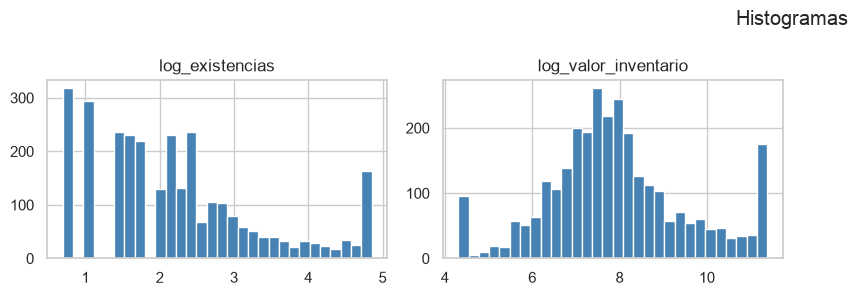

In [ ]:
display(df[num_cols].skew().round(3).to_frame("skewness").sort_values("skewness"))
df[num_cols].hist(figsize=(16, 3*nrow), bins=30, layout=(nrow, ncol), color="steelblue")
plt.suptitle("Histogramas"); plt.tight_layout(); plt.show()

# REGRESIÓN LINEAL SIMPLE
## 3. Análisis de correlación
Se calcula la matriz de correlación de Pearson y se identifica el par de variables con **mayor correlación**.

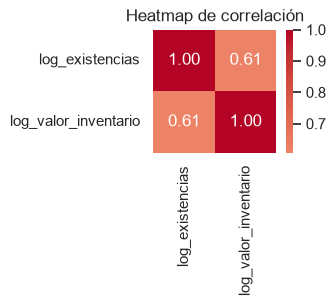

,var1,var2,r,|r|
0,log_existencias,log_valor_inventario,0.606942,0.606942


In [ ]:
corr = df[num_cols].corr()
plt.figure(figsize=(1+0.8*len(num_cols), 0.8*len(num_cols)))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Heatmap de correlación"); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().dropna().reset_index())
pares.columns = ["var1", "var2", "r"]
pares["|r|"] = pares["r"].abs()
pares = pares.sort_values("|r|", ascending=False)
display(pares.head(10))

Variable dependiente (Y): log_valor_inventario
Variable independiente (X): log_existencias
Correlación r = 0.6069


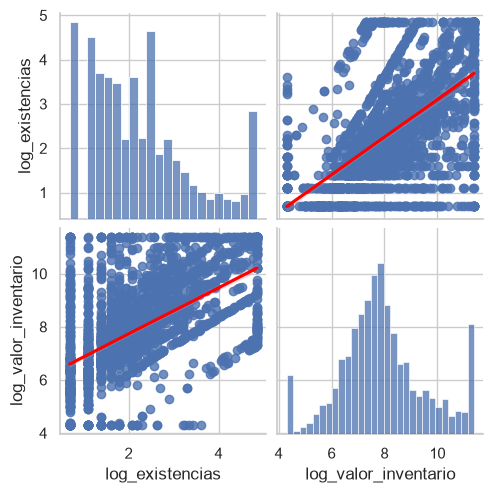

In [ ]:
if Y_LINEAL is not None:
    y_var = Y_LINEAL
    x_var = corr[y_var].drop(y_var).abs().idxmax()
else:
    v1, v2 = pares.iloc[0][["var1", "var2"]]
    # si alguna se llama CLV/valor se toma como dependiente
    y_var = next((v for v in (v1, v2) if any(k in v.lower() for k in ["clv", "valor", "value"])), v2)
    x_var = v1 if y_var == v2 else v2
print(f"Variable dependiente (Y): {y_var}")
print(f"Variable independiente (X): {x_var}")
print(f"Correlación r = {corr.loc[x_var, y_var]:.4f}")

sns.pairplot(df[[x_var, y_var]], kind="reg", plot_kws={"line_kws": {"color": "red"}})
plt.show()

## 4. Modelo de regresión lineal simple

In [ ]:
X_s = sm.add_constant(df[[x_var]])
modelo_simple = sm.OLS(df[y_var], X_s).fit()
print(modelo_simple.summary())

b0, b1 = modelo_simple.params
print(f"\nEcuación:  {y_var} = {b0:.4f} + ({b1:.4f}) · {x_var}")
print(f"R² = {modelo_simple.rsquared:.4f}  |  R = {np.sqrt(modelo_simple.rsquared):.4f}")
if x_var.startswith("log_") and y_var.startswith("log_"):
    interp = (f"Como ambas variables están en logaritmo, b1 es una elasticidad: si {x_var[4:]} aumenta 1 %, "
              f"{y_var[4:]} aumenta aproximadamente {b1:.4f} %.")
elif y_var.startswith("log_"):
    interp = f"Por cada unidad que aumenta {x_var}, {y_var[4:]} cambia aproximadamente {100*b1:.2f} %."
else:
    interp = f"Por cada unidad que aumenta {x_var}, {y_var} cambia en {b1:.4f} unidades."
print("Interpretación:", interp)

                             OLS Regression Results                             
Dep. Variable:     log_valor_inventario   R-squared:                       0.368
Model:                              OLS   Adj. R-squared:                  0.368
Method:                   Least Squares   F-statistic:                     1720.
Date:                  Mon, 19 Oct 2026   Prob (F-statistic):          1.44e-296
Time:                          12:09:20   Log-Likelihood:                -4904.5
No. Observations:                  2951   AIC:                             9813.
Df Residuals:                      2949   BIC:                             9825.
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               5.

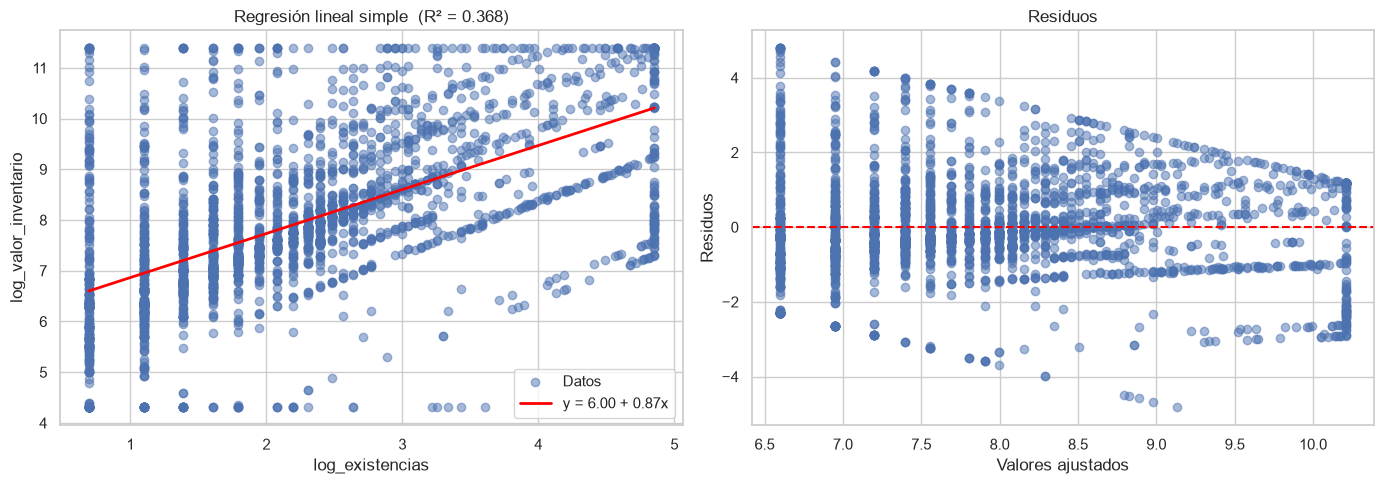

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(df[x_var], df[y_var], alpha=.5, label="Datos")
xs = np.linspace(df[x_var].min(), df[x_var].max(), 100)
ax[0].plot(xs, b0 + b1*xs, color="red", lw=2, label=f"y = {b0:.2f} + {b1:.2f}x")
ax[0].set_xlabel(x_var); ax[0].set_ylabel(y_var); ax[0].legend()
ax[0].set_title(f"Regresión lineal simple  (R² = {modelo_simple.rsquared:.3f})")

ax[1].scatter(modelo_simple.fittedvalues, modelo_simple.resid, alpha=.5)
ax[1].axhline(0, color="red", ls="--")
ax[1].set_xlabel("Valores ajustados"); ax[1].set_ylabel("Residuos"); ax[1].set_title("Residuos")
plt.tight_layout(); plt.show()

# REGRESIÓN LINEAL MÚLTIPLE
## 5. Mejor modelo de regresión lineal múltiple
1. Se usan todas las numéricas, binarias y las categóricas convertidas a *dummies*.
2. Se eliminan predictores con **multicolinealidad** alta (VIF > 10).
3. **Eliminación hacia atrás (backward)**: se quita la variable con mayor p-value hasta que todas sean significativas (p < 0.05).

In [ ]:
X_m = pd.get_dummies(df.drop(columns=[y_var]), drop_first=True).astype(float)
X_m = X_m.loc[:, X_m.std() > 0]
y_m = df[y_var]

# 1) VIF
def calc_vif(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i+1) for i in range(X.shape[1])],
                     index=X.columns)

while X_m.shape[1] > 1:
    vif = calc_vif(X_m)
    if vif.max() <= 10: break
    peor = vif.idxmax()
    if peor == x_var: peor = vif.drop(x_var).idxmax()
    print(f"Se elimina {peor} (VIF = {vif.max():.1f})")
    X_m = X_m.drop(columns=peor)

# 2) Backward por p-value
while True:
    mod = sm.OLS(y_m, sm.add_constant(X_m)).fit()
    p = mod.pvalues.drop("const")
    if p.max() < 0.05 or X_m.shape[1] == 1: break
    print(f"Se elimina {p.idxmax()} (p = {p.max():.4f})")
    X_m = X_m.drop(columns=p.idxmax())

modelo_multiple = mod
print(modelo_multiple.summary())

Se elimina marca_Vita (VIF = 233.8)
Se elimina marca_Scheftner (p = 0.8452)
Se elimina marca_Parmex (p = 0.1337)
Se elimina marca_Dess (p = 0.1045)
Se elimina marca_Schick (p = 0.0915)
                             OLS Regression Results                             
Dep. Variable:     log_valor_inventario   R-squared:                       0.644
Model:                              OLS   Adj. R-squared:                  0.642
Method:                   Least Squares   F-statistic:                     252.8
Date:                  Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                          12:09:27   Log-Likelihood:                -4056.6
No. Observations:                  2951   AIC:                             8157.
Df Residuals:                      2929   BIC:                             8289.
Df Model:                            21                                         
Covariance Type:              nonrobust                                         
     

Ecuación del modelo múltiple:
 log_valor_inventario = 5.4148 + (0.9620)·log_existencias + (0.9896)·marca_Aidite + (1.8784)·marca_Amann Girrbach + (1.1797)·marca_Anax Dent + (3.9673)·marca_Apple + (1.8472)·marca_Arma Dental + (2.1626)·marca_Asiga + (0.6780)·marca_Creation + (1.7259)·marca_Cyberpuerta + (2.1686)·marca_Dekema + (1.5511)·marca_Dentine + (4.6581)·marca_Durr Dental + (3.3817)·marca_Exocad + (1.4070)·marca_Hass + (-2.3520)·marca_Huge + (1.0499)·marca_Jensen + (2.9746)·marca_Medit + (0.9622)·marca_Phrozen + (2.4799)·marca_Quatro + (2.9298)·marca_Renfert + (1.8841)·marca_Roko

R² = 0.6445 | R² ajustado = 0.6419


,VIF final
log_existencias,1.47
marca_Aidite,1.29
marca_Amann Girrbach,1.05
marca_Anax Dent,1.02
marca_Apple,1.00
marca_Arma Dental,1.00
marca_Asiga,1.00
marca_Creation,1.05
marca_Cyberpuerta,1.00
marca_Dekema,1.00


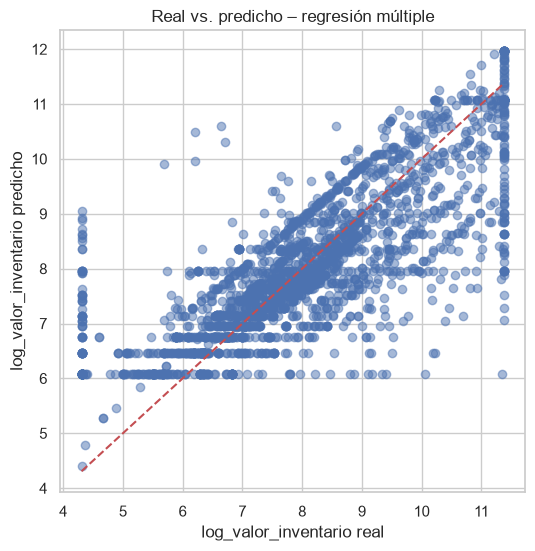

In [ ]:
coefs = modelo_multiple.params
ecuacion = f"{y_var} = {coefs['const']:.4f}" + "".join(
    f" + ({v:.4f})·{k}" for k, v in coefs.drop("const").items())
print("Ecuación del modelo múltiple:\n", ecuacion)
print(f"\nR² = {modelo_multiple.rsquared:.4f} | R² ajustado = {modelo_multiple.rsquared_adj:.4f}")

display(calc_vif(X_m).round(2).to_frame("VIF final"))

plt.figure(figsize=(6, 6))
plt.scatter(y_m, modelo_multiple.fittedvalues, alpha=.5)
lims = [y_m.min(), y_m.max()]; plt.plot(lims, lims, "r--")
plt.xlabel(f"{y_var} real"); plt.ylabel(f"{y_var} predicho")
plt.title("Real vs. predicho – regresión múltiple"); plt.show()

### 5.1 Comparación de coeficientes: modelo simple vs. múltiple

In [ ]:
comp = pd.DataFrame({
    "Simple": modelo_simple.params,
    "Múltiple": modelo_multiple.params,
})
comp.loc["R²"] = [modelo_simple.rsquared, modelo_multiple.rsquared]
comp.loc["R² ajustado"] = [modelo_simple.rsquared_adj, modelo_multiple.rsquared_adj]
comp.loc["AIC"] = [modelo_simple.aic, modelo_multiple.aic]
display(comp.round(4))

if x_var in modelo_multiple.params:
    s, m = modelo_simple.params[x_var], modelo_multiple.params[x_var]
    print(f"El coeficiente de {x_var} pasa de {s:.4f} (simple) a {m:.4f} (múltiple), "
          f"un cambio de {100*(m-s)/abs(s):.1f} %.")
    print("Esto ocurre porque en el modelo múltiple el efecto se controla por las demás variables;"
          " parte de la relación que el modelo simple atribuía a X se explica ahora por otros predictores.")
else:
    print(f"{x_var} dejó de ser significativa al controlar por las demás variables.")
mejora = modelo_multiple.rsquared_adj - modelo_simple.rsquared_adj
print(f"El R² ajustado mejora en {mejora:.4f} con el modelo múltiple.")

,Simple,Múltiple
const,5.9981,5.4148
log_existencias,0.8677,0.9620
marca_Aidite,NaN,0.9896
marca_Amann Girrbach,NaN,1.8784
marca_Anax Dent,NaN,1.1797
marca_Apple,NaN,3.9673
marca_Arma Dental,NaN,1.8472
marca_Asiga,NaN,2.1626
marca_Creation,NaN,0.6780
marca_Cyberpuerta,NaN,1.7259


El coeficiente de log_existencias pasa de 0.8677 (simple) a 0.9620 (múltiple), un cambio de 10.9 %.
Esto ocurre porque en el modelo múltiple el efecto se controla por las demás variables; parte de la relación que el modelo simple atribuía a X se explica ahora por otros predictores.
El R² ajustado mejora en 0.2738 con el modelo múltiple.


# REGRESIÓN LOGÍSTICA
## 6. Regresión logística sobre una variable dicotómica con reponderación de clases y oversampling
Se compara:
- **Modelo base** (sin balancear)
- **Reponderación de clases** (`class_weight='balanced'`)
- **Oversampling** (se duplican aleatoriamente registros de la clase minoritaria, solo en entrenamiento)

No hay variables dicotómicas en la base: se crea valor_inventario_alto = 1 si valor_inventario está en el 25 % más alto.
Importante: log_valor_inventario se EXCLUYE de los predictores, porque de ella se construyó la variable objetivo.
Variable dicotómica: valor_inventario_alto  (1 = 1)


,n,%
log_valor_inventario,,
0,2213,74.99
1,738,25.01


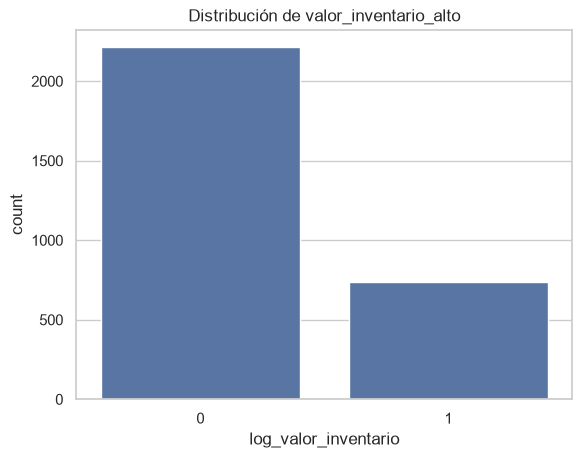

In [ ]:
if VARIABLE_DICOTOMICA is not None:
    y_log_var = VARIABLE_DICOTOMICA
    y_log = df[y_log_var]
elif bin_cols:
    # la binaria más desbalanceada es la que más se beneficia del balanceo
    y_log_var = min(bin_cols, key=lambda c: df[c].value_counts(normalize=True).min())
    y_log = df[y_log_var]
else:
    # no hay dicotómicas: se crea una a partir de la Y lineal (Alto/Bajo, percentil 75)
    nombre = y_var[4:] if y_var.startswith("log_") else y_var
    y_log_var = f"{nombre}_alto"
    y_log = (df[y_var] > df[y_var].quantile(.75)).astype(int)
    print(f"No hay variables dicotómicas en la base: se crea {y_log_var} = 1 si {nombre} está en el 25 % más alto.")
    print(f"Importante: {y_var} se EXCLUYE de los predictores, porque de ella se construyó la variable objetivo.")

clases = sorted(y_log.unique(), key=str)
y_log = (y_log == clases[-1]).astype(int)   # 1 = segunda categoría
print(f"Variable dicotómica: {y_log_var}  (1 = {clases[-1]})")
display(y_log.value_counts().to_frame("n").assign(**{"%": lambda d: (100*d.n/d.n.sum()).round(2)}))

sns.countplot(x=y_log); plt.title(f"Distribución de {y_log_var}"); plt.show()

Predictores: ['log_existencias', 'marca_Aidite', 'marca_Amann Girrbach', 'marca_Anax Dent', 'marca_Apple', 'marca_Arma Dental', 'marca_Asiga', 'marca_Creation', 'marca_Cyberpuerta', 'marca_Dekema', 'marca_Dentine', 'marca_Dess', 'marca_Durr Dental', 'marca_Exocad', 'marca_Hass', 'marca_Huge', 'marca_Jensen', 'marca_Medit', 'marca_Parmex', 'marca_Phrozen', 'marca_Quatro', 'marca_Renfert', 'marca_Roko', 'marca_Scheftner', 'marca_Schick', 'marca_Vita']
Entrenamiento tras oversampling: {0: 1660, 1: 1660}


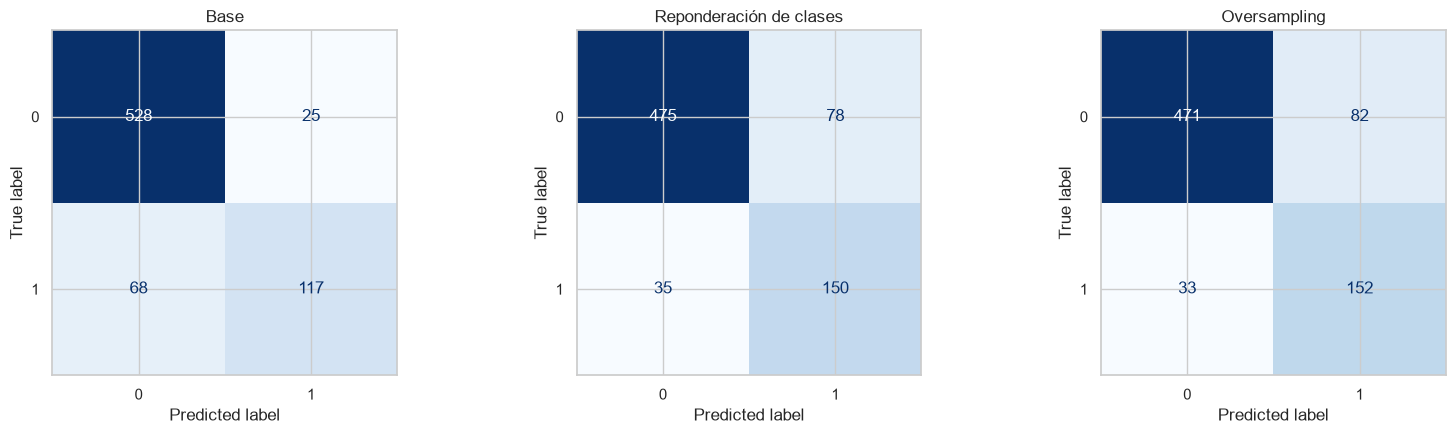

,Accuracy,Precisión (1),Recall (1),F1 (1),AUC
Modelo,,,,,
Base,0.8740,0.8239,0.6324,0.7156,0.9074
Reponderación de clases,0.8469,0.6579,0.8108,0.7264,0.9084
Oversampling,0.8442,0.6496,0.8216,0.7255,0.9082


Con clases desbalanceadas el accuracy engaña: el recall y F1 de la clase minoritaria muestran que reponderar u oversamplear mejora la detección de la clase 1.


In [ ]:
excluir_l = [c for c in [y_log_var] if c in df] + ([y_var] if y_log_var.endswith("_alto") and y_log_var not in df else [])
X_l = pd.get_dummies(df.drop(columns=excluir_l), drop_first=True).astype(float)
X_l = X_l.loc[:, X_l.std() > 0]
print("Predictores:", list(X_l.columns))
X_tr, X_te, y_tr, y_te = train_test_split(X_l, y_log, test_size=.25, stratify=y_log, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

# Oversampling (solo en entrenamiento)
tr = pd.DataFrame(X_tr_s, columns=X_l.columns); tr["y"] = y_tr.values
mayor = tr[tr.y == tr.y.mode()[0]]; menor = tr[tr.y != tr.y.mode()[0]]
menor_up = resample(menor, replace=True, n_samples=len(mayor), random_state=RANDOM_STATE)
tr_os = pd.concat([mayor, menor_up]).sample(frac=1, random_state=RANDOM_STATE)
print("Entrenamiento tras oversampling:", tr_os.y.value_counts().to_dict())

modelos = {
    "Base": LogisticRegression(max_iter=1000).fit(X_tr_s, y_tr),
    "Reponderación de clases": LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_tr_s, y_tr),
    "Oversampling": LogisticRegression(max_iter=1000).fit(tr_os.drop(columns="y").values, tr_os.y),
}

res = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nom, m) in zip(axes, modelos.items()):
    pred = m.predict(X_te_s); prob = m.predict_proba(X_te_s)[:, 1]
    rep = classification_report(y_te, pred, output_dict=True, zero_division=0)
    res.append([nom, accuracy_score(y_te, pred), rep["1"]["precision"], rep["1"]["recall"],
                rep["1"]["f1-score"], roc_auc_score(y_te, prob)])
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred)).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nom)
plt.tight_layout(); plt.show()

tabla = pd.DataFrame(res, columns=["Modelo", "Accuracy", "Precisión (1)", "Recall (1)", "F1 (1)", "AUC"]).set_index("Modelo")
display(tabla.round(4))
print("Con clases desbalanceadas el accuracy engaña: el recall y F1 de la clase minoritaria"
      " muestran que reponderar u oversamplear mejora la detección de la clase 1.")

Coeficientes del mejor modelo (Reponderación de clases), variables estandarizadas:


,coef,odds_ratio
marca_Huge,-0.9065,0.4039
marca_Vita,-0.6426,0.5259
marca_Dess,-0.2194,0.8030
marca_Cyberpuerta,-0.1341,0.8745
marca_Parmex,-0.1292,0.8788
marca_Scheftner,-0.0974,0.9072
marca_Arma Dental,-0.0687,0.9336
marca_Creation,0.0620,1.0639
marca_Dentine,0.0738,1.0766
marca_Schick,0.0759,1.0788


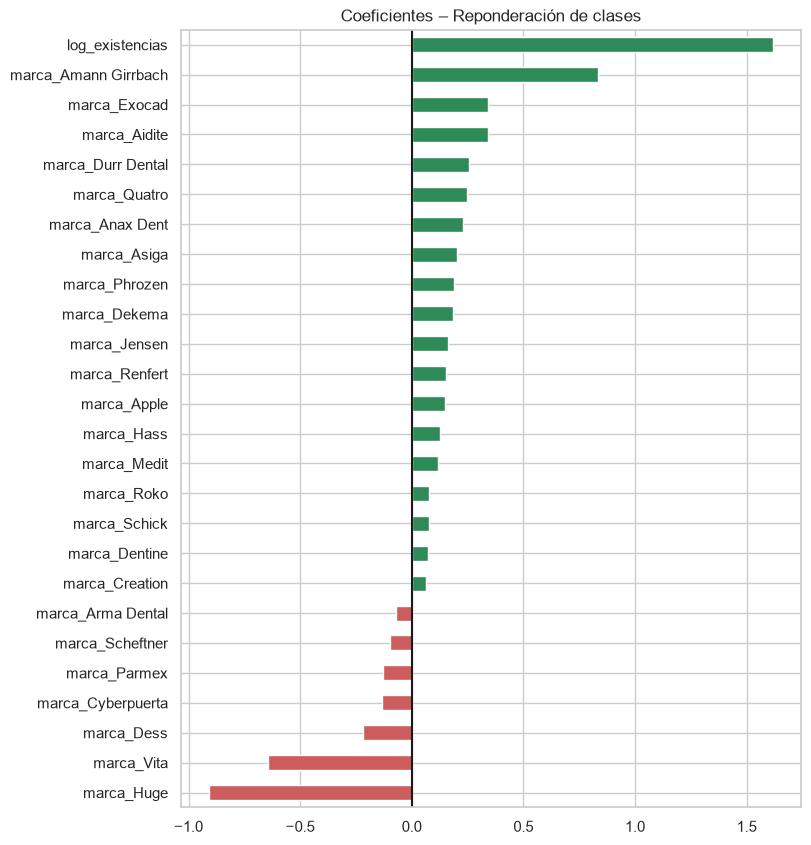

In [ ]:
mejor = tabla["F1 (1)"].idxmax()
coef = pd.DataFrame({"coef": modelos[mejor].coef_[0], "odds_ratio": np.exp(modelos[mejor].coef_[0])},
                    index=X_l.columns).sort_values("coef")
print(f"Coeficientes del mejor modelo ({mejor}), variables estandarizadas:")
display(coef.round(4))
coef["coef"].plot.barh(figsize=(8, 0.35*len(coef)+1), color=np.where(coef["coef"]>0, "seagreen", "indianred"))
plt.title(f"Coeficientes – {mejor}"); plt.axvline(0, color="k"); plt.show()

## 7. Conversión de variables a dicotómicas + Regresión logística
Se convierten los predictores a variables **dicotómicas (0/1)**:
- Numéricas continuas → `1` si el valor es mayor a su **mediana** (Alto), `0` si no (Bajo).
- Categóricas → *dummies* (una columna 0/1 por categoría, quitando una de referencia).
- Binarias → se recodifican a 0/1.

Con estas variables se ajusta la regresión logística (statsmodels) para interpretar los **odds ratios**.

In [ ]:
D = pd.DataFrame(index=df.index)
for c in df.columns:
    if c in excluir_l: continue
    if c in num_cols:
        D[f"{c}_alto"] = (df[c] > df[c].median()).astype(int)
    elif c in bin_cols:
        D[f"{c}_{sorted(df[c].unique(), key=str)[-1]}"] = (df[c] == sorted(df[c].unique(), key=str)[-1]).astype(int)
D = pd.concat([D, pd.get_dummies(df[[c for c in cat_cols if c not in excluir_l]], drop_first=True).astype(int)], axis=1)
D = D.loc[:, D.std() > 0]
print("Variables dicotómicas creadas:", D.shape[1]); display(D.head())

# Pesos de clase para compensar el desbalance
w = y_log.map(len(y_log) / (2 * y_log.value_counts()))
logit = sm.GLM(y_log, sm.add_constant(D.astype(float)), family=sm.families.Binomial(),
               freq_weights=w).fit()
print(logit.summary())

Variables dicotómicas creadas: 26


,log_existencias_alto,marca_Aidite,marca_Amann Girrbach,marca_Anax Dent,marca_Apple,marca_Arma Dental,marca_Asiga,marca_Creation,marca_Cyberpuerta,marca_Dekema,marca_Dentine,marca_Dess,marca_Durr Dental,marca_Exocad,marca_Hass,marca_Huge,marca_Jensen,marca_Medit,marca_Parmex,marca_Phrozen,marca_Quatro,marca_Renfert,marca_Roko,marca_Scheftner,marca_Schick,marca_Vita
0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


                  Generalized Linear Model Regression Results                   
Dep. Variable:     log_valor_inventario   No. Observations:                 2951
Model:                              GLM   Df Residuals:                     2924
Model Family:                  Binomial   Df Model:                           26
Link Function:                    Logit   Scale:                          1.0000
Method:                            IRLS   Log-Likelihood:                -1180.5
Date:                  Mon, 19 Oct 2026   Deviance:                       2361.0
Time:                          12:09:49   Pearson chi2:                 2.91e+03
No. Iterations:                      22   Pseudo R-squ. (CS):             0.4436
Covariance Type:              nonrobust                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const       

,coef,odds_ratio,IC 2.5%,IC 97.5%,p-value
marca_Durr Dental,47.1322,2.946245e+20,0.0000,inf,0.9995
marca_Apple,47.1322,2.946245e+20,0.0000,inf,0.9995
marca_Exocad,46.8166,2.148845e+20,0.0000,inf,0.9994
marca_Quatro,44.7712,2.779043e+19,0.0000,inf,0.9994
marca_Dekema,26.0756,2.111024e+11,0.0000,inf,0.9996
marca_Medit,25.9205,1.807646e+11,0.0000,inf,0.9996
marca_Renfert,24.9520,6.863080e+10,0.0000,inf,0.9996
marca_Amann Girrbach,24.6797,5.227198e+10,0.0000,inf,0.9996
marca_Arma Dental,24.6643,5.147310e+10,0.0000,inf,0.9996
marca_Asiga,24.5313,4.506177e+10,0.0000,inf,0.9997


Variables significativas (p < 0.05): 1
 • log_existencias_alto: aumenta los momios de valor_inventario_alto=1 en un factor de 10.60

AUC: 0.8907
              precision    recall  f1-score   support

           0       0.91      0.90      0.91      2213
           1       0.72      0.73      0.72       738

    accuracy                           0.86      2951
   macro avg       0.81      0.82      0.82      2951
weighted avg       0.86      0.86      0.86      2951



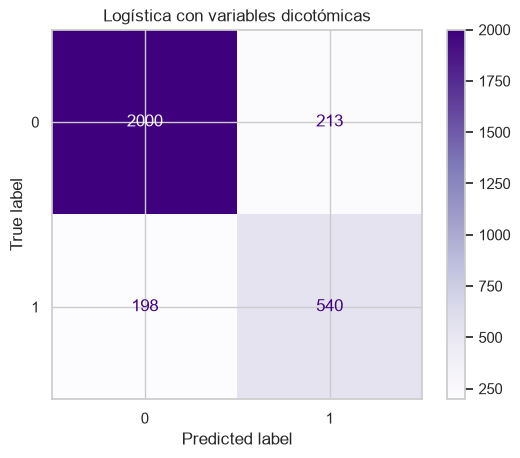

In [ ]:
or_tab = pd.DataFrame({
    "coef": logit.params, "odds_ratio": np.exp(logit.params),
    "IC 2.5%": np.exp(logit.conf_int()[0]), "IC 97.5%": np.exp(logit.conf_int()[1]),
    "p-value": logit.pvalues}).drop("const").sort_values("odds_ratio", ascending=False)
display(or_tab.round(4))

sig = or_tab[or_tab["p-value"] < .05]
print(f"Variables significativas (p < 0.05): {len(sig)}")
for v, r in sig.iterrows():
    efecto = "aumenta" if r.odds_ratio > 1 else "disminuye"
    print(f" • {v}: {efecto} los momios de {y_log_var}=1 en un factor de {r.odds_ratio:.2f}")

prob = logit.predict(sm.add_constant(D.astype(float)))
pred = (prob > .5).astype(int)
print("\nAUC:", round(roc_auc_score(y_log, prob), 4))
print(classification_report(y_log, pred, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_log, pred)).plot(cmap="Purples")
plt.title("Logística con variables dicotómicas"); plt.show()